# DS2002 Midterm: Walmart Hurricane Analytics

**Solo project, Kabir Minhas (GitHub: Kminhas21).** One notebook, run top to bottom: data loading, cleaning pipeline, decision log, SKU consolidation, weather API, Questions 1-5, reflection.

**Weather source:** Open-Meteo historical archive, base URL `https://archive-api.open-meteo.com/v1/archive` (free, no key). Hourly weather is requested in UTC and converted to US Eastern to match the sales timestamps (naive local time).

**Conventions:** Baseline window = Sept 1-15 (flat period); surge window = Sept 19-25, the 7 days before landfall day (Sept 26, Hurricane Helene, an external fact not in the data). Rows with no timestamp cannot be placed in any window and are excluded from date-based work.

## 1. Data loading

All four CSVs are loaded with pandas, both SQLite tables are read with `sqlite3`, and the weather is pulled from the API in section 5. The profile below is the messy data before any cleaning.

In [1]:
import os
import pandas as pd
import numpy as np

DATA_DIR = next(d for d in ('data', '../data', '../../data') if os.path.isdir(d))
MISSING_TOKENS = {'', 'null', 'n/a', 'na', 'nan', 'none'}
DECISION_LOG = []

def log_decision(step, decision, rows_touched, rows_before=None, rows_after=None):
    DECISION_LOG.append({'step': step, 'decision': decision, 'rows_touched': int(rows_touched),
                         'rows_before': rows_before, 'rows_after': rows_after})


In [2]:
import sqlite3

tx_raw = pd.read_csv(os.path.join(DATA_DIR, 'walmart_transactions.csv'), dtype=str)
stores_raw = pd.read_csv(os.path.join(DATA_DIR, 'store_locations.csv'))
catalog = pd.read_csv(os.path.join(DATA_DIR, 'product_catalog (1).csv'))
dcs = pd.read_csv(os.path.join(DATA_DIR, 'distribution_centers.csv'))
con = sqlite3.connect(os.path.join(DATA_DIR, 'inventory_and_sales.db'))
daily_sales_raw = pd.read_sql('SELECT * FROM daily_sales_summary', con)
inventory_raw = pd.read_sql('SELECT * FROM inventory_levels', con)
con.close()

for name, df in [('walmart_transactions', tx_raw), ('store_locations', stores_raw), ('product_catalog', catalog),
                 ('distribution_centers', dcs), ('daily_sales_summary (sqlite)', daily_sales_raw), ('inventory_levels (sqlite)', inventory_raw)]:
    print(f'=== {name}: {len(df):,} rows x {len(df.columns)} columns | nulls {int(df.isnull().sum().sum())} | exact duplicate rows {int(df.duplicated().sum())}')
print()
print('transactions: distinct store_id', tx_raw['store_id'].nunique(), '| category', tx_raw['category'].nunique(),
      '| sku', tx_raw['sku'].nunique(), '| product_name', tx_raw['product_name'].nunique(), '| missing timestamps', int(tx_raw['timestamp'].isna().sum()))


=== walmart_transactions: 25,562 rows x 8 columns | nulls 886 | exact duplicate rows 30
=== store_locations: 14 rows x 8 columns | nulls 2 | exact duplicate rows 0
=== product_catalog: 45 rows x 7 columns | nulls 18 | exact duplicate rows 0
=== distribution_centers: 5 rows x 8 columns | nulls 1 | exact duplicate rows 0
=== daily_sales_summary (sqlite): 3,600 rows x 5 columns | nulls 0 | exact duplicate rows 0
=== inventory_levels (sqlite): 4,320 rows x 6 columns | nulls 626 | exact duplicate rows 0

transactions: distinct store_id 60 | category 37 | sku 45 | product_name 63 | missing timestamps 886


## 2. Cleaning pipeline

One function per cleaning decision, each logging what it did. Row counts before and after are printed; the store join is checked to lose no rows.

In [3]:
CATEGORY_MAP = {
    'alcohol': 'Alcohol', 'alcoholic beverages': 'Alcohol',
    'baby': 'Baby', 'baby products': 'Baby',
    'breakfast': 'Breakfast', 'breakfast foods': 'Breakfast',
    'electronics': 'Electronics',
    'emergency': 'Emergency', 'emergency supplies': 'Emergency',
    'entertainment': 'Entertainment', 'games & entertainment': 'Entertainment',
    'grocery': 'Grocery', 'groceries': 'Grocery',
    'health': 'Health', 'health & wellness': 'Health',
    'household': 'Household', 'household essentials': 'Household',
    'snacks': 'Snacks',
}
TS_FORMATS = ['%Y-%m-%d %H:%M:%S', '%Y-%m-%dT%H:%M:%S', '%m/%d/%Y %H:%M',
              '%d-%b-%Y %H:%M', '%m-%d-%Y %H:%M:%S']

def load_transactions():
    return pd.read_csv(os.path.join(DATA_DIR, 'walmart_transactions.csv'), dtype=str)

def standardize_missing(df):
    """Strip whitespace; turn '', NULL, N/A, NaN... into real NaN."""
    out = df.copy()
    touched = 0
    for c in out.columns:
        s = out[c].str.strip()
        newly_na = s.str.lower().isin(MISSING_TOKENS) & out[c].notna()
        touched += int(newly_na.sum())
        out[c] = s.mask(newly_na)
    log_decision('missing', 'strip whitespace; blank/NULL/N-A tokens -> NaN (cells, not rows)', touched, len(df), len(out))
    return out

def remove_duplicates(df):
    n0 = len(df)
    out = df.drop_duplicates()
    log_decision('duplicates', 'drop exact duplicate rows (keep first)', n0 - len(out), n0, len(out))
    n1 = len(out)
    out = out.drop_duplicates('transaction_id')
    log_decision('duplicates', 'drop repeated transaction_id (keep first)', n1 - len(out), n1, len(out))
    return out

def clean_unit_price(df):
    out = df.copy()
    raw = out['unit_price']
    dollar = int(raw.str.contains('$', regex=False, na=False).sum())
    out['unit_price'] = pd.to_numeric(raw.str.replace('$', '', regex=False).str.replace(',', '', regex=False), errors='coerce')
    bad = int(out['unit_price'].isna().sum() - raw.isna().sum())
    log_decision('unit_price', "remove '$', cast text -> float", dollar, len(df), len(out))
    log_decision('unit_price', 'values that still failed numeric cast -> NaN', bad, len(df), len(out))
    return out

def clean_quantity(df):
    out = df.copy()
    out['quantity'] = pd.to_numeric(out['quantity'], errors='coerce')
    n0 = len(out)
    out = out[out['quantity'] > 0]
    log_decision('quantity', 'drop rows with negative/zero/unparseable quantity (entry errors; sign-flip not assumed)', n0 - len(out), n0, len(out))
    return out

def parse_timestamps(df):
    out = df.copy()
    ts = pd.Series(pd.NaT, index=out.index, dtype='datetime64[ns]')
    for fmt in TS_FORMATS:
        todo = ts.isna() & out['timestamp'].notna()
        ts[todo] = pd.to_datetime(out.loc[todo, 'timestamp'], format=fmt, errors='coerce')
    unparsed = int((ts.isna() & out['timestamp'].notna()).sum())
    missing = int(out['timestamp'].isna().sum())
    out['timestamp'] = ts
    log_decision('timestamp', f'parse {len(TS_FORMATS)} mixed formats into one datetime (naive local time); {unparsed} unparseable', int(ts.notna().sum()), len(df), len(out))
    log_decision('timestamp', 'missing timestamps kept (NaT) but excluded from any date-based analysis; not imputed', missing, len(df), len(out))
    return out

def clean_store_id(df):
    out = df.copy()
    raw = out['store_id']
    out['store_id'] = (raw.str.upper().str.replace('_', '-', regex=False)
                          .str.replace(r'^FL-?(\d{3})$', r'FL-\1', regex=True))
    log_decision('store_id', "uppercase, strip, '_'/missing '-' -> canonical 'FL-###'", int((raw != out['store_id']).sum()), len(df), len(out))
    return out

def clean_category(df):
    out = df.copy()
    raw = out['category']
    out['category'] = raw.str.lower().map(CATEGORY_MAP)
    log_decision('category', f'collapse {raw.nunique()} spellings into {out["category"].nunique()} canonical categories', int((raw != out['category']).sum()), len(df), len(out))
    return out

def clean_transactions():
    DECISION_LOG.clear()
    df = load_transactions()
    for step in (standardize_missing, remove_duplicates, clean_unit_price, clean_quantity,
                 parse_timestamps, clean_store_id, clean_category):
        df = step(df)
    df['product_name_raw'] = df['product_name']
    return df.reset_index(drop=True)

def clean_stores():
    s = pd.read_csv(os.path.join(DATA_DIR, 'store_locations.csv'), dtype={'zip_code': str})
    n0 = len(s)
    s['store_id'] = (s['store_id'].str.strip().str.upper().str.replace('_', '-', regex=False)
                     .str.replace(r'^FL-?(\d{3})$', r'FL-\1', regex=True))
    s = s.drop_duplicates('store_id').reset_index(drop=True)
    log_decision('stores', 'canonicalise store_id and drop duplicate store rows', n0 - len(s), n0, len(s))
    changed = int((s['state'] != 'FL').sum())
    s['state'] = 'FL'
    log_decision('stores', "normalise state ('Florida', 'Fla.') to 'FL'", changed, len(s), len(s))
    # Tallahassee has no coordinates; approximate city-centre values filled in (needed for the weather call)
    fill = {'FL-619': (30.4383, -84.2807)}
    for sid, (lat, lon) in fill.items():
        m = (s['store_id'] == sid) & s['latitude'].isna()
        s.loc[m, ['latitude', 'longitude']] = (lat, lon)
    log_decision('stores', 'fill missing lat/lon for Tallahassee (FL-619) with approximate city-centre coordinates', len(fill), len(s), len(s))
    return s


In [4]:
raw_tx = load_transactions()
print('transactions rows before cleaning:', len(raw_tx))
tx_clean = clean_transactions()
print('transactions rows after cleaning: ', len(tx_clean), f'({len(raw_tx) - len(tx_clean)} rows removed)')
stores = clean_stores()
joined = tx_clean.merge(stores, on='store_id', how='left', validate='many_to_one', indicator=True)
assert len(joined) == len(tx_clean) and (joined['_merge'] == 'both').all(), 'some transactions did not match a store'
print('store join check: all', len(joined), 'transactions matched one of', len(stores), 'stores')
ts = tx_clean['timestamp'].dropna()
assert ts.dt.year.eq(2024).all() and ts.dt.month.eq(9).all()
assert tx_clean['transaction_id'].is_unique and (tx_clean['quantity'] > 0).all()
tx_clean.head()


transactions rows before cleaning: 25562


transactions rows after cleaning:  25402 (160 rows removed)
store join check: all 25402 transactions matched one of 12 stores


,transaction_id,store_id,timestamp,sku,product_name,category,quantity,unit_price,product_name_raw
0,TXN012636,FL-710,2024-09-24 09:48:13,PNUTBTR-16,PEANUT BUTTER,Grocery,1,3.15,PEANUT BUTTER
1,TXN000759,FL-412,2024-09-13 20:30:20,CNSOUP-01,CANNED SOUP,Grocery,1,2.02,CANNED SOUP
2,TXN003338,FL-105,2024-09-17 10:06:00,TOILETPAPER12,Toilet Paper 12-Roll,Household,2,10.47,Toilet Paper 12-Roll
3,TXN025020,FL-330,2024-09-11 06:29:08,ROKU-STD,Roku Streaming Stick,Electronics,1,28.59,Roku Streaming Stick
4,TXN015797,FL-302,2024-09-26 15:59:42,BEER-24,Light Beer 24pk,Alcohol,3,18.82,Light Beer 24pk


Sanity chart of daily order volume. A zero day or a day many times the norm would point at a cleaning bug rather than the hurricane.

days: 30 | zero days: 0 | rows used 24,521 of 25,402 (the rest have no timestamp)


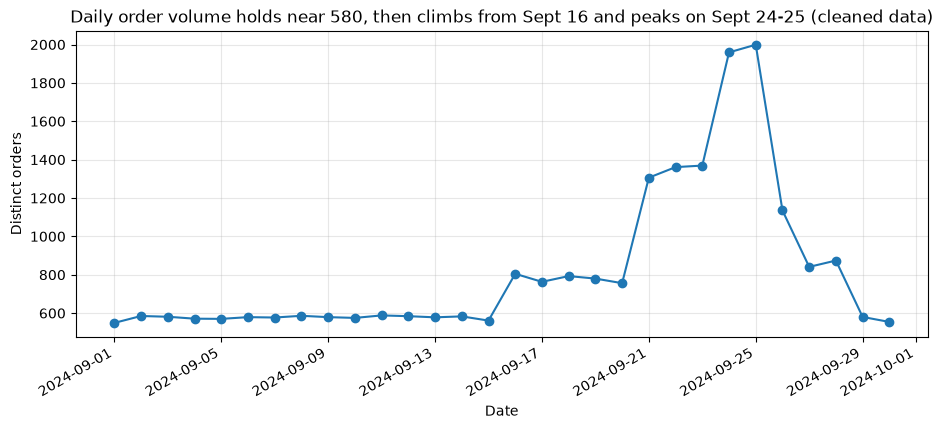

In [5]:
import matplotlib.pyplot as plt
import seaborn as sns

dated = tx_clean.dropna(subset=['timestamp']).assign(day=lambda x: x['timestamp'].dt.normalize())
daily = dated.groupby('day')['transaction_id'].nunique()
print(f'days: {len(daily)} | zero days: {int((daily == 0).sum())} | rows used {len(dated):,} of {len(tx_clean):,} (the rest have no timestamp)')

fig, ax = plt.subplots(figsize=(11, 4.5))
ax.plot(daily.index, daily.values, marker='o')
ax.set_title('Daily order volume holds near 580, then climbs from Sept 16 and peaks on Sept 24-25 (cleaned data)')
ax.set_xlabel('Date'); ax.set_ylabel('Distinct orders')
ax.grid(alpha=.3); fig.autofmt_xdate(); plt.show()


## 3. Decision log

Every cleaning decision, what it did, and how many rows (or cells, for the missing-value step) it touched.

In [6]:
pd.set_option('display.max_colwidth', 110)
pd.set_option('display.width', 200)
decision_log = pd.DataFrame(DECISION_LOG)
decision_log

,step,decision,rows_touched,rows_before,rows_after
0,missing,"strip whitespace; blank/NULL/N-A tokens -> NaN (cells, not rows)",0,25562,25562
1,duplicates,drop exact duplicate rows (keep first),30,25562,25532
2,duplicates,drop repeated transaction_id (keep first),0,25532,25532
3,unit_price,"remove '$', cast text -> float",3026,25532,25532
4,unit_price,values that still failed numeric cast -> NaN,0,25532,25532
5,quantity,drop rows with negative/zero/unparseable quantity (entry errors; sign-flip not assumed),130,25532,25402
6,timestamp,parse 5 mixed formats into one datetime (naive local time); 0 unparseable,24521,25402,25402
7,timestamp,missing timestamps kept (NaT) but excluded from any date-based analysis; not imputed,881,25402,25402
8,store_id,"uppercase, strip, '_'/missing '-' -> canonical 'FL-###'",3590,25402,25402
9,category,collapse 37 spellings into 10 canonical categories,18649,25402,25402


**Judgement calls:** negative quantities were dropped rather than sign-flipped (nothing marks them as returns); the rows with no timestamp were kept but excluded from date-based work instead of being imputed; Tallahassee's missing store coordinates were filled with approximate city-centre values (needed for the weather call).